<a href="https://colab.research.google.com/github/zineelabdineimane/23009051-zineelabdine-CI/blob/main/notebooks/ZINE_EL_ABDINE_IMANE_CI_22%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zineelabdineimane/23009051-zineelabdine-CI/blob/main/notebooks/ZINE_EL_ABDINE_IMANE_CI_22%20(1).ipynb)


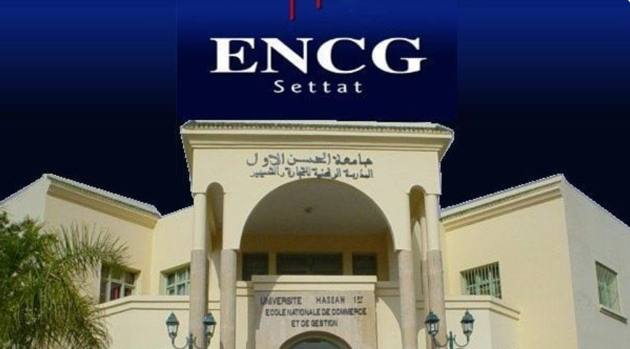

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CI22 est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** ZINE EL ABDINE Imane · **Code Apogée :** 23009051 · **Groupe :** CI  
**Sujet :** CI22 — Partenaires commerciaux du Maroc · **Date :** 19/11/2026  
**Dépôt :** https://github.com/zineelabdineimane/23009051-zineelabdine-CI.git

## 0. Configuration et reproductibilité
Exécutez la cellule ci-dessous avant les autres.

In [1]:
import sys, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)   # chemins relatifs
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__,
      "| numpy:", np.__version__, "| sklearn:", sklearn.__version__)

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | sklearn: 1.6.1


## 1. Sujet et problématique
**Intérêt économique :** le Maroc échange avec des dizaines de partenaires très différents (Union européenne, Afrique, Asie, Amériques, Golfe) : certains sont de grands clients, d'autres de grands fournisseurs, d'autres encore des marchés petits mais en forte croissance. Regrouper les partenaires selon la *structure* de leurs échanges avec le Maroc permet à un exportateur de repérer des marchés au profil comparable, et à un décideur d'identifier les dépendances (fournisseurs dominants, soldes très déséquilibrés) et les marchés à développer.

**Problématique précise :** peut-on regrouper les partenaires commerciaux du Maroc en groupes homogènes **et stables**, à partir de la structure de leurs échanges (taille des flux d'exportation et d'importation, solde commercial, croissance) ?

**Nature de la tâche :** apprentissage non supervisé — partitionnement (clustering).

**Objectif mesurable annoncé avant l'expérimentation :**
1. silhouette moyenne du modèle retenu **≥ 0,25** ;
2. stabilité : indice de Rand ajusté (ARI) moyen **> 0,70** entre le partitionnement de référence et ceux obtenus sur des sous-échantillons de 80 % des partenaires ;
3. modèle supérieur aux références naïves (partition aléatoire, règle par taille d'échanges, k = 2) en silhouette ;
4. groupes interprétables économiquement.

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade Plus — https://comtradeplus.un.org/ 19/11/2026 / By subscribing to the United Nations COMTRADE or using UN Comtrade without subscription, you are agreeing to abide by all of the following terms and conditions for your use of United Nations COMTRADE, in addition to and without derogating from the standard Terms of Use for United Nations Web Sites (available at https://www.un.org/en/about-us/terms-of-use):
- **Période et fréquence :** 2015 et 2023 (deux années seulement), annuelle
- **Pays déclarant / partenaire / flux / code SH (version) :** déclarant = Maroc ; partenaires = tous ; flux = exportations (X) et importations (M) ; produit = **TOTAL (tous produits)**, `cmdCode = TOTAL` ; classification : H4 (HS 2012) pour 2015 et H6 (HS 2022) pour 2023 (champ `classificationCode`) — seule la ligne TOTAL étant utilisée, le changement de nomenclature n'a pas d'effet
- **Devise / unités :** dollars américains courants (USD), valeur commerciale (`primaryValue`)
- **Une ligne du fichier brut représente :** un (année, flux, partenaire, chapitre SH). **Une ligne du tableau analysé représente :** un partenaire.

**Variables construites** (période récente = jusqu'à 3 dernières années disponibles, ici **2023** seule ; période initiale = jusqu'à 3 premières années, ici **2015** seule) :

| Variable | Description | Type / unité | Rôle |
|---|---|---|---|
| `log_exp` | log(1 + exportations marocaines vers le partenaire), moyenne période récente | numérique, log USD | explicative |
| `log_imp` | log(1 + importations marocaines depuis le partenaire), moyenne période récente | numérique, log USD | explicative |
| `solde_rel` | (X − M) / (X + M), dans [−1 ; 1] | numérique, sans unité | explicative |
| `croiss_exp` | log(X 2023) − log(X 2015), bornée à [−3 ; 3] | numérique, log-croissance | explicative |
| `croiss_imp` | log(M 2023) − log(M 2015), bornée à [−3 ; 3] | numérique, log-croissance | explicative |

Seules 5 variables sont construites car l'extraction ne contient que le total tous produits : la diversification (HHI) et la part agroalimentaire ne sont pas calculables. Les pourcentages de valeurs manquantes sont calculés dans la cellule de la section 3.

In [ ]:
# ====== CHARGEMENT ======
# Placez l'extraction Comtrade (CSV) dans data/raw/ (chemin relatif). Sous Colab, si le fichier est
# absent, une fenêtre de téléversement s'ouvre.
NOM = "comtrade_maroc.csv"
CANDIDATS = [Path("data/raw") / NOM, Path(NOM), Path("/content") / NOM, Path("/content/data/raw") / NOM,
             Path("/content/drive/MyDrive") / NOM]
CHEMIN_CSV = next((p for p in CANDIDATS if p.exists()), None)

if CHEMIN_CSV is None:
    try:
        from google.colab import files          # uniquement sous Colab
        print("Fichier introuvable : téléversez l'extraction Comtrade (.csv).")
        up = files.upload()
        CHEMIN_CSV = Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError(f"Déposez {NOM} dans data/raw/ (chemin relatif).")
print("Fichier utilisé :", CHEMIN_CSV)

df_raw = pd.read_csv(CHEMIN_CSV, low_memory=False)
print("Dimensions du fichier brut :", df_raw.shape)
print("Colonnes :", list(df_raw.columns))
display(df_raw.head())

COLONNES_REQ = ["refYear", "flowCode", "partnerCode", "partnerDesc", "cmdCode", "primaryValue"]
manquantes = [c for c in COLONNES_REQ if c not in df_raw.columns]
assert not manquantes, f"Colonnes absentes {manquantes} : adapter les noms (voir la liste ci-dessus)."

Fichier introuvable : téléversez l'extraction Comtrade (.csv).


## 3. Exploration et trois figures interprétées
Vérifications demandées : doublons *année–flux–partenaire–produit*, unités, valeurs nulles, agrégats de partenaires (« World », « nes »…), niveau de nomenclature SH.

In [ ]:
# ====== QUALITÉ ET NETTOYAGE (chaque décision est affichée) ======
df = df_raw.copy()
n0 = len(df)

# 1) Lignes agrégées de mode de transport / douane / partenaire 2 : garder le total
if "customsCode" in df.columns:
    df = df[df["customsCode"].astype(str).str.strip() == "C00"]
for col in ["motCode", "partner2Code"]:
    if col in df.columns:
        df = df[pd.to_numeric(df[col], errors="coerce") == 0]
print(f"Après filtre totaux douane/transport/partenaire2 : {len(df)} lignes (sur {n0})")

# 2) Flux : exportations (X) et importations (M) uniquement (on exclut ré-exportations RX / RM)
df = df[df["flowCode"].isin(["X", "M"])]

# 3) Partenaires agrégés ou non géographiques : exclus
motif = r"World|\bnes\b|Free Zones|Special Categories|Bunkers|Unspecified|Areas"
est_agrege = (pd.to_numeric(df["partnerCode"], errors="coerce") == 0) | df["partnerDesc"].astype(str).str.contains(motif, case=False, regex=True)
print("Partenaires agrégés exclus :", sorted(df.loc[est_agrege, "partnerDesc"].astype(str).unique()))
df = df[~est_agrege]

# 4) Niveau SH : chapitres à 2 chiffres si disponibles, sinon ligne TOTAL
df["cmdCode"] = df["cmdCode"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
df["cmdCode"] = np.where(df["cmdCode"].str.fullmatch(r"\d{1,2}"), df["cmdCode"].str.zfill(2), df["cmdCode"])
A_SH2 = df["cmdCode"].str.fullmatch(r"\d{2}").any()
df = df[df["cmdCode"].str.fullmatch(r"\d{2}")] if A_SH2 else df[df["cmdCode"].str.upper() == "TOTAL"]
print("Niveau SH utilisé :", "SH2 (chapitres)" if A_SH2 else "TOTAL seulement (HHI et part agro indisponibles)")

# 5) Valeurs manquantes / nulles / négatives
df["primaryValue"] = pd.to_numeric(df["primaryValue"], errors="coerce")
n_inv = (df["primaryValue"].isna() | (df["primaryValue"] <= 0)).sum()
df = df[df["primaryValue"] > 0]
print("Lignes à valeur manquante, nulle ou négative supprimées :", int(n_inv))

# 6) Doublons sur la clé année-flux-partenaire-produit
cle = ["refYear", "flowCode", "partnerCode", "cmdCode"]
n_dup = int(df.duplicated(cle).sum())
print("Doublons sur la clé", cle, ":", n_dup, "-> agrégés par somme" if n_dup else "")
df = df.groupby(cle, as_index=False).agg(primaryValue=("primaryValue", "sum"),
                                         partnerDesc=("partnerDesc", "first"))
ANNEES = sorted(int(a) for a in df["refYear"].unique())
print("Années disponibles :", ANNEES, "| partenaires :", df["partnerCode"].nunique(), "| lignes propres :", len(df))

In [ ]:
# ====== CONSTRUCTION DU TABLEAU PAR PARTENAIRE ======
AN_MAX, AN_MIN = max(ANNEES), min(ANNEES)
REC  = lambda d: d[d["refYear"] >= AN_MAX - 2]     # 3 dernières années
INIT = lambda d: d[d["refYear"] <= AN_MIN + 2]     # 3 premières années
TOP_N = 60                                          # on garde les 60 premiers partenaires (X+M récents)

def flux_moyen(d, flux):
    # moyenne annuelle des valeurs (USD) d'un flux par partenaire, sur la sous-période d
    s = d[d["flowCode"] == flux].groupby(["partnerCode", "refYear"])["primaryValue"].sum()
    return s.groupby(level=0).mean()

def hhi_et_agro(d, flux):
    s = d[d["flowCode"] == flux].groupby(["partnerCode", "cmdCode"])["primaryValue"].sum()
    part = s / s.groupby(level=0).transform("sum")
    hhi = (part ** 2).groupby(level=0).sum()
    agro_mask = pd.to_numeric(part.index.get_level_values(1), errors="coerce") <= 24
    agro = part[agro_mask].groupby(level=0).sum()
    return hhi, agro

X_rec, M_rec = flux_moyen(REC(df), "X"), flux_moyen(REC(df), "M")
X_ini, M_ini = flux_moyen(INIT(df), "X"), flux_moyen(INIT(df), "M")
tab = pd.concat({"X_rec": X_rec, "M_rec": M_rec, "X_ini": X_ini, "M_ini": M_ini}, axis=1)
tab[["X_rec", "M_rec"]] = tab[["X_rec", "M_rec"]].fillna(0.0)
tab = tab.loc[(tab["X_rec"] + tab["M_rec"]).sort_values(ascending=False).head(TOP_N).index]

noms = df.drop_duplicates("partnerCode").set_index("partnerCode")["partnerDesc"]
tab["partenaire"] = noms.reindex(tab.index).values

tab["log_exp"]   = np.log1p(tab["X_rec"])
tab["log_imp"]   = np.log1p(tab["M_rec"])
tab["solde_rel"] = (tab["X_rec"] - tab["M_rec"]) / (tab["X_rec"] + tab["M_rec"])
# croissance : NaN si le flux initial est absent (imputé plus tard, DANS le pipeline)
tab["croiss_exp"] = (np.log1p(tab["X_rec"]) - np.log1p(tab["X_ini"])).where(tab["X_ini"] > 0).clip(-3, 3)
tab["croiss_imp"] = (np.log1p(tab["M_rec"]) - np.log1p(tab["M_ini"])).where(tab["M_ini"] > 0).clip(-3, 3)

if A_SH2:
    hhi_x, agro_x = hhi_et_agro(REC(df), "X")
    _,     agro_m = hhi_et_agro(REC(df), "M")
    tab["hhi_exp"]       = hhi_x.reindex(tab.index)
    tab["part_agro_exp"] = agro_x.reindex(tab.index)
    tab["part_agro_imp"] = agro_m.reindex(tab.index)

VARS = [v for v in ["log_exp", "log_imp", "solde_rel", "croiss_exp", "croiss_imp",
                    "hhi_exp", "part_agro_exp", "part_agro_imp"] if v in tab.columns]
tab = tab.set_index("partenaire")
# part_agro : absence de flux agricole = 0 (et non manquant) ; HHI manquant si aucun export
for v in ["part_agro_exp", "part_agro_imp"]:
    if v in tab: tab[v] = tab[v].fillna(0.0)
X = tab[VARS].copy()

print("Période récente :", sorted(int(a) for a in REC(df)['refYear'].unique()), "| période initiale :", sorted(int(a) for a in INIT(df)['refYear'].unique()))
print("Tableau analysé :", X.shape, "(partenaires x variables)")
manq = X.isna().mean().mul(100).round(1).rename("% manquants")
display(pd.concat([X.dtypes.rename("type"), manq], axis=1))
display(X.describe().T.round(3))

In [ ]:
# ====== FIGURE 1 — distribution des échanges ======
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(X["log_exp"], bins=15, color="#1f77b4", edgecolor="white")
ax[0].set_title("Figure 1a — Exportations marocaines par partenaire"); ax[0].set_xlabel("log(1 + USD), moyenne récente"); ax[0].set_ylabel("Nombre de partenaires")
ax[1].hist(X["log_imp"], bins=15, color="#d62728", edgecolor="white")
ax[1].set_title("Figure 1b — Importations marocaines par partenaire"); ax[1].set_xlabel("log(1 + USD), moyenne récente"); ax[1].set_ylabel("Nombre de partenaires")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_1_distribution.png", dpi=150); plt.show()

**Figure 1 — Interprétation :** les montants échangés s'étalent sur plusieurs ordres de grandeur (de l'ordre de quelques milliers à plus de 10 milliards USD), ce qui justifie l'échelle logarithmique : sans elle, quelques très gros partenaires écraseraient les autres. Les exportations (médiane de log ≈ 19,1) sont étalées de 14 à 23, avec plusieurs partenaires de petite taille ; les importations (médiane ≈ 19,7) sont plus concentrées autour de 19–21 et comportent une valeur extrême à gauche (≈ 8, soit quelques milliers de dollars), qui correspond à Djibouti. Cette valeur atypique pourra perturber le partitionnement.

In [ ]:
# ====== FIGURE 2 — corrélations entre variables ======
corr = X.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=45, ha="right")
ax.set_yticks(range(len(VARS))); ax.set_yticklabels(VARS); ax.grid(False)
for i in range(len(VARS)):
    for j in range(len(VARS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Corrélation de Pearson")
ax.set_title("Figure 2 — Corrélations entre variables (partenaires)")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_2_correlations.png", dpi=150); plt.show()

**Figure 2 — Interprétation :** aucune paire de variables n'a une corrélation supérieure à 0,6 en valeur absolue : il n'y a pas de redondance extrême. Les plus fortes sont `solde_rel` avec `log_exp` (+0,57) et avec `log_imp` (−0,55), ce qui est attendu car le solde est calculé à partir des deux flux. Les tailles d'exportation et d'importation sont peu liées (+0,19) : ce sont deux dimensions distinctes du profil d'un partenaire. La croissance des importations est négativement liée aux deux tailles (≈ −0,3) : effet de base, les petits fournisseurs progressent plus vite ; la croissance des exportations est au contraire liée positivement à `log_exp` (+0,30) et au solde (+0,44). Après standardisation, K-means donnera un poids comparable à chaque variable.

In [ ]:
# ====== FIGURE 3 — taille des échanges et solde ======
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(X["log_imp"], X["log_exp"], c=X["solde_rel"], cmap="RdYlBu", s=60, edgecolor="k", linewidth=0.4)
plt.colorbar(sc, label="Solde relatif (X − M)/(X + M)")
for nom in (tab["X_rec"] + tab["M_rec"]).sort_values(ascending=False).head(10).index:
    ax.annotate(nom, (X.loc[nom, "log_imp"], X.loc[nom, "log_exp"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Importations : log(1 + USD)"); ax.set_ylabel("Exportations : log(1 + USD)")
ax.set_title("Figure 3 — Exportations vs importations par partenaire (couleur = solde relatif)")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_3_export_import.png", dpi=150); plt.show()

**Figure 3 — Interprétation :** l'Espagne et la France, en haut à droite, sont à la fois les plus gros clients et les plus gros fournisseurs, avec un solde proche de l'équilibre. Autour d'eux se trouvent l'Italie, l'Allemagne, le Royaume-Uni, les États-Unis, la Türkiye, le Brésil et l'Inde. La Chine est un cas particulier : importations très élevées et exportations bien plus faibles, donc un fort déficit pour le Maroc (point rouge foncé). À gauche, des points bleus montrent des partenaires pour lesquels le Maroc est en excédent avec peu d'importations, et Djibouti est isolé à l'extrême gauche. Des groupes se dessinent déjà : gros partenaires, partenaires de taille moyenne en déficit, partenaires en excédent.

## 4. Préparation et prévention des fuites

| Opération | Décision | Justification |
|---|---|---|
| Lignes agrégées | totaux douane/transport ; partenaires « World », « nes »… exclus | éviter le double comptage |
| Doublons clé année–flux–partenaire–produit | somme si présents | une seule valeur par clé |
| Valeurs nulles / négatives | supprimées | log et parts non définis |
| Nomenclature SH | ligne `TOTAL` (tous produits) uniquement ; versions H4 (2015) et H6 (2023) | pas d'effet du changement de nomenclature sur un total |
| Valeurs manquantes (croissances) | imputation par la **médiane**, dans le `Pipeline` | pas d'information inventée hors pipeline |
| Asymétrie des montants | transformation `log1p` | réduire l'effet des très gros partenaires |
| Croissance extrême | bornée à [−3 ; 3] | limiter l'effet des partenaires quasi nuls au départ |
| Mise à l'échelle | `StandardScaler` dans le `Pipeline` | K-means utilise une distance euclidienne |
| Taille de l'échantillon | 60 premiers partenaires (X + M, période récente) | écarter les partenaires aux flux négligeables |
| Découpage | **pas de train/test** : non supervisé, aucune cible | remplacé par un protocole de **stabilité** (sous-échantillons à 80 %, plusieurs graines), où le pipeline est **réajusté** à chaque fois |

**Contrôle de fuite :** aucune variable cible n'existe ; les variables sont calculées avec les seules valeurs observées, et l'imputation et la standardisation font partie du pipeline réajusté lors des tests de stabilité.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def prep():
    return Pipeline([("imputation", SimpleImputer(strategy="median")), ("echelle", StandardScaler())])

def pipe_kmeans(k, n_init=20, seed=GRAINE):
    return Pipeline([("imputation", SimpleImputer(strategy="median")), ("echelle", StandardScaler()),
                     ("kmeans", KMeans(n_clusters=k, n_init=n_init, random_state=seed))])

Z = prep().fit_transform(X)       # matrice standardisée utilisée pour les scores
print("Matrice standardisée :", Z.shape, "| valeurs manquantes restantes :", int(np.isnan(Z).sum()))

## 5. Algorithme principal
**Algorithme / numéro :** K-means (algorithme n° [N° DANS VOTRE LISTE DU COURS, famille partitionnement 17–20]).

**Pourquoi lui ? Alternative écartée ?** K-means convient quand on cherche des groupes compacts de taille comparable dans un espace numérique standardisé : c'est le cas ici (variables continues, partenaires décrits par 5 indicateurs). Il est simple, rapide, et ses centres sont directement interprétables comme des « profils types » de partenaires, ce qui sert l'objectif économique. L'alternative plausible est le **mélange gaussien (GMM)**, qui autorise des groupes de forme et de taille différentes et des appartenances probabilistes ; elle est comparée à K-means dans la section 7, mais pas retenue comme modèle principal, car elle estime beaucoup plus de paramètres (covariances) pour seulement une soixantaine de partenaires. La classification hiérarchique (CHA) est une autre alternative, sensible aux partenaires atypiques.

**Équation principale :** K-means minimise l'inertie intra-groupe

$$ J(C,\mu)=\sum_{k=1}^{K}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^{2},\qquad \mu_k=\frac{1}{|C_k|}\sum_{x_i\in C_k}x_i $$

- $x_i$ : vecteur standardisé des 5 variables du partenaire $i$ ;
- $K$ : nombre de groupes ; $C_k$ : ensemble des partenaires du groupe $k$ ; $|C_k|$ : son effectif ;
- $\mu_k$ : centre (centroïde) du groupe $k$ ; $\lVert\cdot\rVert$ : norme euclidienne.

Le score de **silhouette** d'un partenaire $i$ est $s(i)=\dfrac{b(i)-a(i)}{\max\{a(i),b(i)\}}$ où $a(i)$ est la distance moyenne aux autres membres de son groupe et $b(i)$ la plus petite distance moyenne aux membres d'un autre groupe ; $s(i)\in[-1;1]$.

**Paramètres appris :** les $K$ centres $\mu_k$ et l'affectation de chaque partenaire à un groupe.

**Deux hyperparamètres :** `n_clusters` $K$ (testé de 3 à 8, choisi par la silhouette maximale ; $K=2$ sert de référence) et `n_init` (nombre de redémarrages avec des centres initiaux aléatoires ; testé : 1, 10, 50 ; le meilleur résultat d'inertie est conservé, ce qui limite la sensibilité à l'initialisation).

**Schéma explicatif personnel :** voir la figure ci-dessous (données **simulées**, schéma pédagogique et non résultat).

In [ ]:
# ====== SCHÉMA DE L'ALGORITHME (données simulées : illustration, pas un résultat) ======
rng = np.random.default_rng(GRAINE)
pts = np.vstack([rng.normal(c, 0.55, size=(25, 2)) for c in [(0, 0), (3, 3), (0, 3.5)]])
cent = pts[rng.choice(len(pts), 3, replace=False)]
etapes = []
for it in range(3):
    d = np.linalg.norm(pts[:, None, :] - cent[None, :, :], axis=2)
    lab = d.argmin(1)
    etapes.append((cent.copy(), lab.copy()))
    cent = np.array([pts[lab == k].mean(0) if (lab == k).any() else cent[k] for k in range(3)])
titres = ["1) Initialiser K centres\n2) Affecter chaque point au centre le plus proche",
          "3) Recalculer les centres (moyennes)\npuis ré-affecter", "4) Répéter jusqu'à stabilité\n(J ne diminue plus)"]
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for a, (c, l), t in zip(axs, etapes, titres):
    a.scatter(pts[:, 0], pts[:, 1], c=l, cmap="Set2", s=25)
    a.scatter(c[:, 0], c[:, 1], marker="X", s=180, c="k"); a.set_title(t, fontsize=9)
    a.set_xlabel("variable 1 (standardisée)"); a.set_ylabel("variable 2 (standardisée)")
fig.suptitle("Schéma — Fonctionnement de K-means (X noir = centres ; données simulées)")
plt.tight_layout(); plt.savefig(FIG_DIR / "schema_kmeans.png", dpi=150); plt.show()

## 6. Protocole expérimental
**Références naïves :** (R1) partition **aléatoire** en K groupes (moyenne de 30 tirages) ; (R2) règle simple par **seuil de taille** : K groupes de partenaires par quantiles du commerce total (X + M) ; (R3) K-means avec **K = 2**.

**Protocole :** pas de découpage train/test (aucune cible). Choix de K sur la silhouette, parmi 3 à 8, **règle fixée avant les résultats**. Évaluation de la **stabilité** : (a) 30 sous-échantillons de 80 % des partenaires, pipeline réajusté, groupes prédits pour tous les partenaires et comparés au partitionnement de référence par l'ARI ; (b) 10 graines aléatoires différentes.

**Métrique principale :** silhouette moyenne (plus élevée = groupes mieux séparés).

**Métriques secondaires :** indice de Davies–Bouldin (plus faible = mieux) ; ARI de stabilité.

**Réglage sans test :** K et `n_init` uniquement, sur les critères internes ci-dessus ; il n'existe pas de jeu de test.

In [ ]:
# ====== CHOIX DE K (hyperparamètre 1) ======
lignes = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=GRAINE).fit(Z)
    lignes.append({"K": k, "inertie": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                   "davies_bouldin": davies_bouldin_score(Z, km.labels_)})
sel = pd.DataFrame(lignes).set_index("K")
display(sel.round(3))

# Règle fixée à l'avance : K entre 3 et 8 qui maximise la silhouette (K=2 = référence R3)
K_OPT = int(sel.loc[3:, "silhouette"].idxmax())
print("K retenu :", K_OPT)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sel.index, sel["inertie"], "o-", color="#1f77b4"); ax[0].set_title("Méthode du coude"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertie intra-groupe")
ax[1].plot(sel.index, sel["silhouette"], "o-", color="#2ca02c"); ax[1].axvline(K_OPT, ls="--", color="grey")
ax[1].axhline(0.25, ls=":", color="red", label="objectif 0,25"); ax[1].legend()
ax[1].set_title("Silhouette moyenne"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_4_choix_k.png", dpi=150); plt.show()

# ====== HYPERPARAMÈTRE 2 : n_init ======
rows = []
for ni in [1, 10, 50]:
    scores = [silhouette_score(Z, KMeans(K_OPT, n_init=ni, random_state=s).fit_predict(Z)) for s in range(10)]
    rows.append({"n_init": ni, "silhouette moyenne (10 graines)": np.mean(scores), "écart-type": np.std(scores)})
display(pd.DataFrame(rows).round(4))

In [ ]:
# ====== MODÈLE PRINCIPAL ET RÉFÉRENCES ======
modele = pipe_kmeans(K_OPT).fit(X)
labels = modele.predict(X)
sil_km = silhouette_score(Z, labels); db_km = davies_bouldin_score(Z, labels)

# R1 : partition aléatoire (30 tirages)
rng = np.random.default_rng(GRAINE)
sil_alea = []
while len(sil_alea) < 30:
    lab_alea = rng.integers(0, K_OPT, len(Z))
    if len(set(lab_alea)) > 1:                       # silhouette exige au moins 2 groupes
        sil_alea.append(silhouette_score(Z, lab_alea))
sil_r1 = float(np.mean(sil_alea))
# R2 : quantiles du commerce total
tot = (tab["X_rec"] + tab["M_rec"]).values
lab_r2 = pd.qcut(pd.Series(tot).rank(method="first"), K_OPT, labels=False).values
sil_r2, db_r2 = silhouette_score(Z, lab_r2), davies_bouldin_score(Z, lab_r2)
# R3 : K-means avec K=2
lab_r3 = KMeans(2, n_init=20, random_state=GRAINE).fit_predict(Z)
sil_r3, db_r3 = silhouette_score(Z, lab_r3), davies_bouldin_score(Z, lab_r3)
# Alternative : GMM (covariance diagonale, adaptée au petit effectif)
gmm = GaussianMixture(n_components=K_OPT, covariance_type="diag", n_init=10, random_state=GRAINE).fit(Z)
lab_g = gmm.predict(Z)
sil_g, db_g = silhouette_score(Z, lab_g), davies_bouldin_score(Z, lab_g)

# ====== STABILITÉ ======
rng = np.random.default_rng(GRAINE)
ari_sous = []
for b in range(30):
    idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
    pb = pipe_kmeans(K_OPT, seed=b).fit(X.iloc[idx])            # imputation + échelle réajustées
    ari_sous.append(adjusted_rand_score(labels, pb.predict(X)))
ari_graines = [adjusted_rand_score(labels, pipe_kmeans(K_OPT, seed=s).fit_predict(X)) for s in range(10)]
ARI_SOUS, ARI_GR = float(np.mean(ari_sous)), float(np.mean(ari_graines))

resultats = pd.DataFrame([
    {"Méthode": f"R1 Aléatoire (K={K_OPT})", "Silhouette": sil_r1, "Davies-Bouldin": np.nan, "ARI stabilité": np.nan},
    {"Méthode": f"R2 Règle taille d'échanges (K={K_OPT})", "Silhouette": sil_r2, "Davies-Bouldin": db_r2, "ARI stabilité": np.nan},
    {"Méthode": "R3 K-means K=2", "Silhouette": sil_r3, "Davies-Bouldin": db_r3, "ARI stabilité": np.nan},
    {"Méthode": f"GMM diag (K={K_OPT})", "Silhouette": sil_g, "Davies-Bouldin": db_g, "ARI stabilité": np.nan},
    {"Méthode": f"K-means principal (K={K_OPT})", "Silhouette": sil_km, "Davies-Bouldin": db_km, "ARI stabilité": ARI_SOUS},
]).set_index("Méthode")
display(resultats.round(3))
print(f"ARI moyen sous-échantillons 80 % : {ARI_SOUS:.3f} | ARI moyen entre graines : {ARI_GR:.3f}")
print("Objectif silhouette >= 0,25 :", "ATTEINT" if sil_km >= 0.25 else "NON ATTEINT")
print("Objectif ARI > 0,70         :", "ATTEINT" if ARI_SOUS > 0.70 else "NON ATTEINT")
print("Meilleur que les références  :", "OUI" if sil_km > max(sil_r1, sil_r2, sil_r3) else "NON (voir analyse)")

## 7. Résultats et interprétation
Le tableau ci-dessus est calculé par le code (aucun score saisi à la main). **Valeurs obtenues à l'exécution** (recopiez celles de VOTRE sortie ; elles doivent être identiques puisque la graine est fixée) :

| Méthode | Silhouette | Davies-Bouldin | ARI stabilité | Interprétation |
|---|---:|---:|---:|---|
| R1 Aléatoire (K=6) | −0,142 | – | – | négative : une partition au hasard ne sépare rien |
| R2 Règle par taille (K=6) | −0,049 | 4,057 | – | trier par taille d'échanges ne reproduit pas les profils |
| R3 K-means K=2 | 0,363 | 1,070 | – | meilleure silhouette, mais deux groupes seulement (peu informatif) |
| GMM diag (K=6) | 0,245 | 1,075 | – | sous l'objectif de 0,25 et moins bon que K-means |
| **K-means retenu (K=6)** | **0,301** | **0,902** | **0,843** | objectifs 1 et 2 atteints ; meilleur Davies-Bouldin de tous |

*(Pas de colonnes « validation / test » : en non supervisé, la validation est interne — silhouette, Davies–Bouldin — et la généralisation est examinée par la stabilité.)*

In [ ]:
# ====== FIGURE 5 — partitionnement projeté (ACP) ======
pca = PCA(n_components=2, random_state=GRAINE).fit(Z)
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(9.5, 6.5))
sc = ax.scatter(P[:, 0], P[:, 1], c=labels, cmap="tab10", s=70, edgecolor="k", linewidth=0.4)
for i in np.argsort(-tot)[:15]:
    ax.annotate(X.index[i], (P[i, 0], P[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.legend(*sc.legend_elements(), title="Groupe", loc="best")
ax.set_xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]:.0%} de la variance)")
ax.set_ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]:.0%} de la variance)")
ax.set_title(f"Figure 5 — Partenaires du Maroc : K-means (K={K_OPT}) projeté par ACP")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_5_clusters_acp.png", dpi=150); plt.show()

# ====== FIGURE 6 — comparaison silhouette modèle / références ======
fig, ax = plt.subplots(figsize=(9, 4))
vals = resultats["Silhouette"]
couleurs = ["#bbbbbb"] * (len(vals) - 1) + ["#2ca02c"]
ax.barh(vals.index, vals.values, color=couleurs); ax.axvline(0.25, ls=":", color="red", label="objectif 0,25")
ax.set_xlabel("Silhouette moyenne"); ax.set_title("Figure 6 — Modèle vs références"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_6_comparaison.png", dpi=150); plt.show()

In [ ]:
# ====== INTERPRÉTATION ÉCONOMIQUE DES GROUPES ======
profil = X.assign(groupe=labels).groupby("groupe").mean().round(2)
profil.insert(0, "effectif", pd.Series(labels).value_counts().sort_index())
display(profil)

zprof = pd.DataFrame(Z, columns=VARS).assign(groupe=labels).groupby("groupe").mean()
fig, ax = plt.subplots(figsize=(9, 3 + 0.5 * K_OPT))
im = ax.imshow(zprof, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=45, ha="right")
ax.set_yticks(range(K_OPT)); ax.set_yticklabels([f"Groupe {g}" for g in zprof.index])
plt.colorbar(im, label="Écart à la moyenne (écarts-types)")
ax.set_title("Figure 7 — Profil moyen standardisé de chaque groupe")
plt.tight_layout(); plt.savefig(FIG_DIR / "figure_7_profils.png", dpi=150); plt.show()

for g in sorted(set(labels)):
    membres = X.index[labels == g].tolist()
    print(f"\nGroupe {g} ({len(membres)}) :", ", ".join(membres))

In [ ]:
# ====== ANALYSE DES ERREURS : partenaires mal classés (silhouette individuelle) ======
from sklearn.metrics import silhouette_samples
ss = pd.Series(silhouette_samples(Z, labels), index=X.index, name="silhouette_individuelle")
err = pd.DataFrame({"groupe": labels, "silhouette_individuelle": ss.round(3)}).sort_values("silhouette_individuelle")
print("Partenaires avec une silhouette négative (probablement mal classés) :", int((ss < 0).sum()), "sur", len(ss))
display(err.head(8))
print("Effectif par groupe :", dict(pd.Series(labels).value_counts().sort_index()))
print("Groupes d'un seul partenaire :", [X.index[labels == g][0] for g in sorted(set(labels)) if (labels == g).sum() == 1])

**Nommer les groupes** (d'après le tableau de profils et la figure 7) :
- **Groupe 0 — « Grands partenaires aux échanges massifs » (15)** : Espagne, France, Chine, États-Unis, Italie, Allemagne, Türkiye, Brésil, Royaume-Uni, Inde… Exportations et importations les plus élevées (log ≈ 21,0 et 21,6), solde modéré (−0,26).
- **Groupe 1 — « Fournisseurs, exportations marocaines en recul » (9)** : Arabie saoudite, Russie, Égypte, Corée du Sud, Singapour, Irlande, Afrique du Sud, Thaïlande, Indonésie. Solde très déficitaire (−0,78) et exportations marocaines en baisse (croissance moyenne −0,92).
- **Groupe 2 — « Partenaires intermédiaires en déficit modéré » (18)** : Émirats arabes unis, Canada, Tchéquie, Argentine, Japon, Suisse, Autriche, Tunisie, Viet Nam… Échanges moyens, solde −0,45, exportations en croissance (+0,96).
- **Groupe 3 — « Clients en excédent pour le Maroc » (8)** : Pakistan, Côte d'Ivoire, Mexique, Hong Kong, Bangladesh, Sénégal, Mauritanie, Australie. Solde positif (+0,76), importations faibles, exportations en forte croissance (+1,32).
- **Groupe 4 — « Fournisseurs dont les ventes au Maroc explosent » (9)** : Bahreïn, Grèce, Lituanie, Trinité-et-Tobago, Kazakhstan, Qatar, Colombie, Oman, Libye. Croissance des importations très forte (+2,44), solde −0,75. *Hypothèse non vérifiée ici* : plusieurs sont des exportateurs d'hydrocarbures ; l'extraction ne contient pas les produits, donc cela reste à confirmer.
- **Groupe 5 — « Valeur atypique » (1)** : Djibouti. Importations quasi nulles (≈ 3 000 USD), solde = +1, croissances plafonnées à 3 : c'est un artefact des données plutôt qu'un vrai profil.

**Analyse de la robustesse et des erreurs :** la stabilité est bonne : ARI moyen de 0,843 sur 30 sous-échantillons de 80 % (objectif > 0,70) et de 1,000 entre graines avec `n_init` = 20. Aucun partenaire n'a de silhouette négative ; les plus proches d'une frontière sont Djibouti (0,00), le Canada (0,03), le Qatar (0,04), l'Argentine (0,06) et la Thaïlande (0,07). **K-means bat la partition aléatoire, la règle par taille et GMM** en silhouette, et il a le meilleur Davies-Bouldin. Il **ne bat pas K = 2 en silhouette** (0,301 contre 0,363) : cette métrique tend à favoriser les partitions à peu de groupes, mais K = 2 est trop grossier pour guider une décision, donc l'objectif 3 n'est que partiellement atteint. **Point de fragilité :** les silhouettes pour K = 3 à 8 sont très proches (0,271 à 0,301) ; le choix de K = 6 est donc peu tranché, et l'un des six groupes est réduit à Djibouti, signe d'une valeur atypique plus que d'un profil économique.

**Utilisation en commerce international :** un exportateur marocain peut regarder les marchés du groupe 3, où le Maroc est en excédent et où les ventes progressent vite, et ceux du groupe 2, de taille moyenne avec des exportations en croissance. Un décideur peut surveiller le groupe 1, où les exportations marocaines reculent, et le groupe 4, où les importations croissent très vite et créent une dépendance potentielle. Ces lectures restent à confirmer avec des données par produit.

## 8. Analyse critique
**Limites des données :** données déclaratives de commerce de marchandises ; les valeurs miroir (déclarées par les partenaires) peuvent différer ; ré-exportations et commerce en transit non traités ; partenaires agrégés (« nes ») exclus ; changement possible de version SH sur la période ; services exclus ; un seul pays déclarant (Maroc). Seuls les 60 premiers partenaires sont retenus ; deux années seulement (2015 et 2023) : la croissance est une variation entre deux dates et dépend de la conjoncture de ces deux années ; aucune information sur la structure par produit (total uniquement) ; la ligne « Other Asia, nes » (qui regroupe généralement Taïwan — à vérifier) est exclue comme agrégat.

**Limites de la méthode :** K-means suppose des groupes compacts et sphériques, est sensible aux valeurs extrêmes et à l'échelle des variables ; le nombre de groupes dépend du critère (silhouette) et n'a pas de « vérité » ; l'échantillon est petit (≈ 60 observations) ; l'ACP ne représente qu'une part de la variance ; les groupes décrivent une structure d'échanges, pas une relation de cause à effet.

**[BROUILLON proposé par l'IA — à vérifier avec VOS sorties, puis à réécrire avec vos mots]** **Deux améliorations concrètes :** (1) enrichir les données : extraire les chapitres SH2 pour calculer la diversification (HHI) et la part agroalimentaire, et utiliser plus de deux années (série annuelle) pour une croissance moins sensible à deux dates ; (2) traiter les valeurs atypiques (retirer Djibouti ou utiliser une mise à l'échelle robuste) puis comparer K-means à la classification hiérarchique avec un choix de K appuyé sur plusieurs critères.

## 9. Conclusion
**Réponse explicite à la problématique :** en partie oui. Les 60 principaux partenaires du Maroc se regroupent en six groupes de silhouette 0,301 et de stabilité (ARI) 0,843, ce qui atteint les deux premiers objectifs. Le modèle fait mieux que les références aléatoire et par taille, mais pas que K = 2 en silhouette, et l'un des groupes est réduit à Djibouti, valeur atypique ; l'objectif global n'est donc que partiellement atteint.

**Objectif atteint ? Valeur commerciale / décisionnelle :** les groupes donnent une première typologie lisible (grands partenaires, clients en excédent, fournisseurs en forte hausse, etc.) utile pour orienter la prospection et repérer des dépendances. La principale limite est de s'appuyer sur deux années et sur le seul total des échanges : sans données par produit, les explications économiques restent des hypothèses.

## 10. Références, reproduction et dépôt
- **Données :** UN Comtrade Plus, https://comtradeplus.un.org/
- **Documentation technique :** scikit-learn — Clustering, https://scikit-learn.org/stable/modules/clustering.html ; scikit-learn — Silhouette, https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
- **Silhouette (article d'origine) :** Rousseeuw, P. J. (1987), *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis*, Journal of Computational and Applied Mathematics, 20, 53–65.
- **GitHub :** https://github.com/zineelabdineimane/23009051-zineelabdine-CI.git
- **Réexécution :** `pip install -r requirements.txt`, puis exécuter les cellules dans l'ordre.



## ✅ Contrôle final
- [ ] Les dix sections sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures commentées, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7